# Task 3: Sales Prediction Model
**Project:** Retail Sales Forecasting | **WeIntern Week 2**

## 1. Objective and corrections
Predict one-day-ahead completed-order sales. This revision keeps the daily forecasting target and the original data; it does not change targets, remove difficult test cases, or invent scores to obtain positive R².

The previous run had negative test R². That is a measured limitation, not a coding error that can always be fixed. This revision adds historical benchmarks, regularization, and validation-based selection. The final test period is used only after selecting the model. Run all cells with the Task 1 cleaned CSV to measure whether performance improves.

**Evaluation:** expanding-window validation within the earliest 80% of days, followed by an untouched final 20%. Lag and rolling features use actual observations through the preceding day. This is a rolling one-day-ahead evaluation, not a multi-day forecast from a single origin.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Load and validate the cleaned dataset
Use the original cleaned CSV. The notebook tries a local file first and then the original Google Drive path. Missing calendar dates are assumed to mean no completed orders; confirm this assumption for real data.

In [3]:
#mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATA_PATH = Path('/content/drive/MyDrive/Week2Assign/retail_sales_cleaned.csv')
local_path = Path('retail_sales_cleaned.csv')
if local_path.is_file():
    DATA_PATH = local_path
elif not DATA_PATH.is_file():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass
if not DATA_PATH.is_file():
    raise FileNotFoundError('Place retail_sales_cleaned.csv beside this notebook or update DATA_PATH.')
OUTPUT_DIR = DATA_PATH.parent / 'Task3_Outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
required = {'order_date', 'sales', 'order_status'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['sales'] = pd.to_numeric(df['sales'], errors='coerce')
if df[['order_date', 'sales', 'order_status']].isna().any().any():
    raise ValueError('Missing/invalid target, date, or order status. Resolve in Task 1 before forecasting.')
if not np.isfinite(df['sales']).all() or (df['sales'] < 0).any():
    raise ValueError('Expected finite, nonnegative sales in this cleaned synthetic dataset.')
print('Dataset dimensions:', df.shape)
print('Order statuses:', df['order_status'].value_counts().to_dict())
display(df.head())

Dataset dimensions: (11928, 21)
Order statuses: {'completed': 11231, 'returned': 480, 'cancelled': 217}


,order_id,order_date,ship_date,store_id,region,customer_segment,product_id,product_name,product_category,quantity,...,discount,promotion,sales,cost_price,shipping_cost,profit,payment_method,sales_channel,holiday_flag,order_status
0,ORD000001,2023-04-08,2023-04-10,ST101,north,consumer,P3001,Running Shoes,fashion,7.0,...,0.082,festival sale,19890.12,1610.25,5.960,8612.41,upi,in-store,0,returned
1,ORD000002,2025-04-28,2025-05-01,ST303,east,consumer,P5001,Skincare Kit,beauty & personal care,3.0,...,0.107,no promotion,4574.92,657.02,100.970,2502.89,cash,online,0,completed
2,ORD000003,2024-12-18,2024-12-18,ST401,west,consumer,P2003,Bedsheet Set,home & kitchen,5.0,...,0.072,no promotion,9323.44,756.38,27.900,5513.64,credit card,in-store,1,completed
3,ORD000004,2024-04-26,2024-04-26,ST501,central,consumer,P1002,Smartphone,electronics,3.0,...,0.192,no promotion,47721.03,13601.43,29.195,6874.41,cash,online,0,completed
4,ORD000005,2024-04-19,2024-04-21,ST301,east,consumer,P1002,Smartphone,electronics,3.0,...,0.081,no promotion,50439.35,14503.70,0.000,6928.25,cash,in-store,0,completed


## 3. Daily completed-order sales

Completed orders: 11231 | Calendar days: 1096


,daily_sales
count,1.096000e+03
mean,1.755824e+05
std,1.627871e+05
min,9.136600e+02
25%,5.416024e+04
50%,1.197269e+05
75%,2.502406e+05
max,1.093490e+06


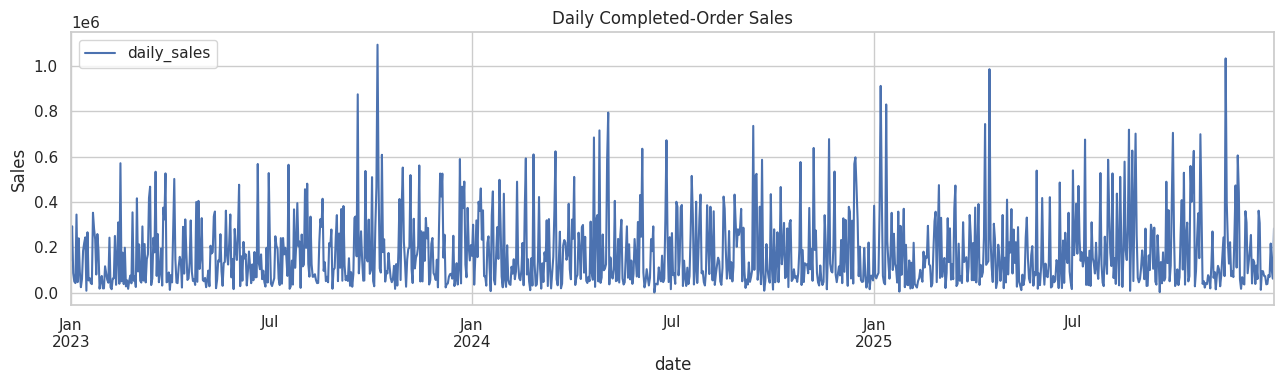

In [5]:
completed = df.loc[df['order_status'].astype(str).str.strip().str.lower().eq('completed')].copy()
if completed.empty:
    raise ValueError('No completed orders found.')
completed['date'] = completed['order_date'].dt.normalize()
calendar = pd.date_range(df['order_date'].min().normalize(), df['order_date'].max().normalize(), freq='D')
sales = completed.groupby('date')['sales'].sum().reindex(calendar, fill_value=0).rename('daily_sales')
daily = sales.rename_axis('date').reset_index()
print('Completed orders:', len(completed), '| Calendar days:', len(daily))
display(sales.describe().to_frame())
daily.plot(x='date', y='daily_sales', figsize=(13, 4), title='Daily Completed-Order Sales')
plt.ylabel('Sales'); plt.tight_layout(); plt.show()

## 4. Historical and calendar features
No profit, same-day quantity, same-day price, or future outcomes are predictors. All rolling statistics start with `shift(1)`. Long windows capture a more stable sales level; median windows are less sensitive to peaks.

In [6]:
features = daily.copy()
for name, values in {
    'day_of_week': daily['date'].dt.dayofweek,
    'month': daily['date'].dt.month,
    'day_of_year': daily['date'].dt.dayofyear,
    'time_index': np.arange(len(daily)),
}.items():
    features[name] = values
for name, period in [('day_of_week', 7), ('month', 12), ('day_of_year', 365.25)]:
    features[name + '_sin'] = np.sin(2 * np.pi * features[name] / period)
    features[name + '_cos'] = np.cos(2 * np.pi * features[name] / period)
for lag in [1, 7, 14, 28]:
    features[f'sales_lag_{lag}'] = sales.shift(lag).to_numpy()
past = sales.shift(1)
for window in [7, 14, 28, 56]:
    for statistic in ['mean', 'median', 'std']:
        features[f'sales_rolling_{statistic}_{window}'] = getattr(past.rolling(window), statistic)().to_numpy()
features['expanding_mean'] = past.expanding(min_periods=56).mean().to_numpy()
model_data = features.dropna().reset_index(drop=True)
feature_columns = [c for c in model_data if c not in ['date', 'daily_sales']]
if len(model_data) < 200:
    raise ValueError('At least 256 calendar days are required for this evaluation design.')
split = int(len(model_data) * 0.8)
train, test = model_data.iloc[:split].copy(), model_data.iloc[split:].copy()
X_train, y_train = train[feature_columns], train['daily_sales']
X_test, y_test = test[feature_columns], test['daily_sales']
print('Train:', len(train), train['date'].min(), 'to', train['date'].max())
print('Test:', len(test), test['date'].min(), 'to', test['date'].max())
print('Features:', len(feature_columns))

Train: 832 2023-02-26 00:00:00 to 2025-06-06 00:00:00
Test: 208 2025-06-07 00:00:00 to 2025-12-31 00:00:00
Features: 27


## 5. Candidate models and historical benchmarks
Yesterday, last week, trailing means, and a historical mean are useful checks on whether machine learning adds value. Ridge regularizes correlated lag features. Histogram gradient boosting and Random Forest provide nonlinear candidates. All candidates are selected by the same validation RMSE; test performance never determines the winner.

In [7]:
estimators = {'Linear Regression': make_pipeline(StandardScaler(), LinearRegression())}
for alpha in [10.0, 100.0, 1000.0, 10000.0]:
    estimators[f'Ridge alpha={alpha:g}'] = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
for leaf in [5, 20]:
    estimators[f'Random Forest leaf={leaf}'] = RandomForestRegressor(
        n_estimators=150, max_depth=8, min_samples_leaf=leaf,
        max_features=0.7, random_state=RANDOM_STATE, n_jobs=-1)
for leaves in [3, 7]:
    estimators[f'Gradient Boosting leaves={leaves}'] = HistGradientBoostingRegressor(
        max_iter=100, max_leaf_nodes=leaves, min_samples_leaf=30,
        learning_rate=0.05, l2_regularization=100.0, random_state=RANDOM_STATE)
benchmarks = {
    'Yesterday': 'sales_lag_1', 'Last week': 'sales_lag_7',
    'Trailing 28-day mean': 'sales_rolling_mean_28',
    'Trailing 56-day mean': 'sales_rolling_mean_56',
    'Historical expanding mean': 'expanding_mean',
    'Training mean': None,
}
def predict_candidate(name, fit_X, fit_y, predict_X):
    if name in benchmarks:
        column = benchmarks[name]
        pred = np.full(len(predict_X), fit_y.mean()) if column is None else predict_X[column].to_numpy()
        return np.maximum(0, pred), None
    fitted = clone(estimators[name]).fit(fit_X, fit_y)
    return np.maximum(0, fitted.predict(predict_X)), fitted

def scores(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'R2': r2_score(y, pred)}

candidates = list(benchmarks) + list(estimators)
cv = TimeSeriesSplit(n_splits=4)
validation_rows = []
for name in candidates:
    actuals, forecasts = [], []
    for fit_idx, val_idx in cv.split(X_train):
        pred, _ = predict_candidate(name, X_train.iloc[fit_idx], y_train.iloc[fit_idx], X_train.iloc[val_idx])
        actuals.extend(y_train.iloc[val_idx].to_numpy())
        forecasts.extend(pred)
    validation_rows.append({'Model': name, **scores(actuals, forecasts)})
validation = pd.DataFrame(validation_rows).sort_values('RMSE').reset_index(drop=True)
best_name = validation.iloc[0]['Model']
print('Selected using validation only:', best_name)
display(validation.round(3))

Selected using validation only: Training mean


,Model,MAE,RMSE,R2
0,Training mean,127953.521,166716.803,-0.008
1,Historical expanding mean,126706.995,166759.239,-0.009
2,Ridge alpha=10000,128052.488,166912.221,-0.010
3,Trailing 56-day mean,129899.294,167525.454,-0.018
4,Gradient Boosting leaves=3,128368.557,168596.299,-0.031
5,Ridge alpha=1000,129756.479,168675.179,-0.032
6,Gradient Boosting leaves=7,130238.852,169336.070,-0.040
7,Trailing 28-day mean,130747.370,169412.214,-0.041
8,Random Forest leaf=20,131053.464,170318.720,-0.052
9,Ridge alpha=100,136308.689,173062.287,-0.086


## 6. Final test evaluation
The chosen candidate is now fitted on all training days. Other test results are diagnostic comparisons only. Keep the selected model even if another candidate happens to score better on this test period. R² can remain negative when daily demand is largely unpredictable.

Validation-selected model: Training mean


,Model,Selected_by_validation,MAE,RMSE,R2
0,Yesterday,False,177304.633,242063.505,-0.818
1,Last week,False,169629.862,234632.296,-0.709
2,Trailing 28-day mean,False,141577.115,185243.569,-0.065
3,Trailing 56-day mean,False,138228.272,180459.613,-0.011
4,Historical expanding mean,False,134456.939,180165.998,-0.007
5,Training mean,True,134726.896,179946.372,-0.005
6,Linear Regression,False,135678.302,187034.406,-0.086
7,Ridge alpha=10,False,135464.940,185600.892,-0.069
8,Ridge alpha=100,False,135903.675,183263.781,-0.042
9,Ridge alpha=1000,False,135528.479,181410.171,-0.021


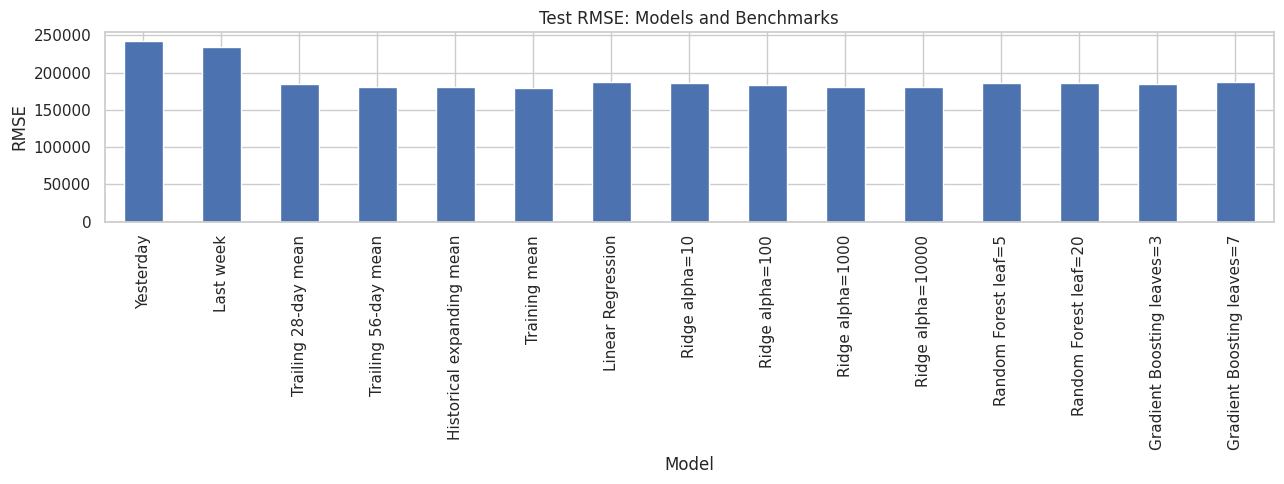

In [8]:
test_rows, fitted_models, test_forecasts = [], {}, {}
for name in candidates:
    pred, fitted = predict_candidate(name, X_train, y_train, X_test)
    fitted_models[name], test_forecasts[name] = fitted, pred
    test_rows.append({'Model': name, 'Selected_by_validation': name == best_name, **scores(y_test, pred)})
comparison = pd.DataFrame(test_rows)
predictions = test_forecasts[best_name]
selected_scores = scores(y_test, predictions)
print('Validation-selected model:', best_name)
display(comparison.round(3))
comparison.plot.bar(x='Model', y='RMSE', figsize=(13, 5), legend=False, title='Test RMSE: Models and Benchmarks')
plt.ylabel('RMSE'); plt.tight_layout(); plt.show()

## 7. Actual versus predicted and residual analysis

,date,actual_sales,predicted_sales,residual,absolute_error
0,2025-06-07,73548.66,175871.12,-102322.46,102322.46
1,2025-06-08,68309.69,175871.12,-107561.43,107561.43
2,2025-06-09,126930.69,175871.12,-48940.43,48940.43
3,2025-06-10,421021.59,175871.12,245150.47,245150.47
4,2025-06-11,22786.64,175871.12,-153084.48,153084.48
5,2025-06-12,27151.97,175871.12,-148719.15,148719.15
6,2025-06-13,73946.07,175871.12,-101925.05,101925.05
7,2025-06-14,45987.91,175871.12,-129883.21,129883.21
8,2025-06-15,56626.62,175871.12,-119244.50,119244.50
9,2025-06-16,143640.73,175871.12,-32230.39,32230.39


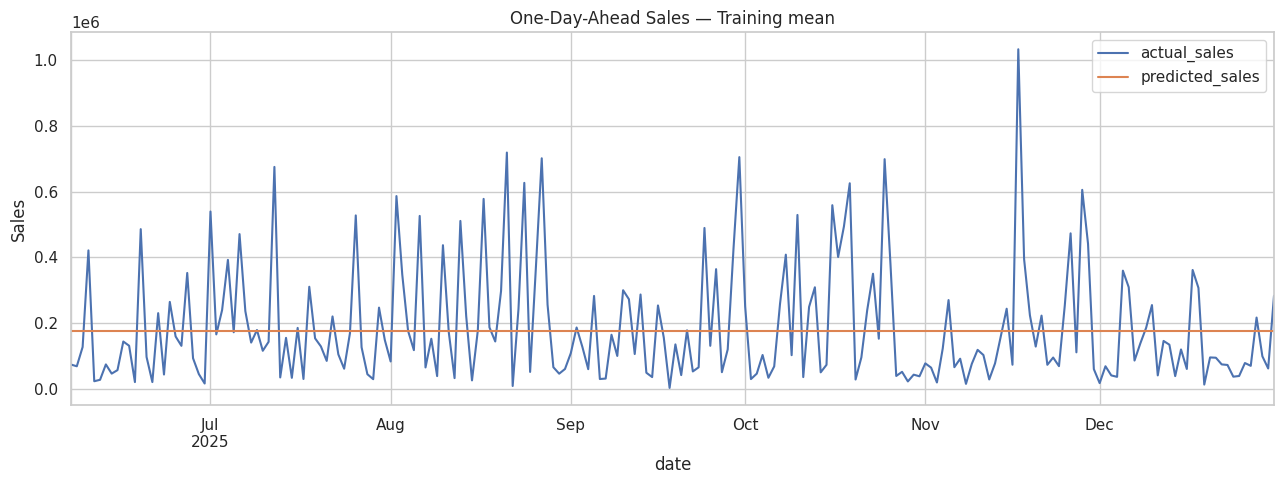

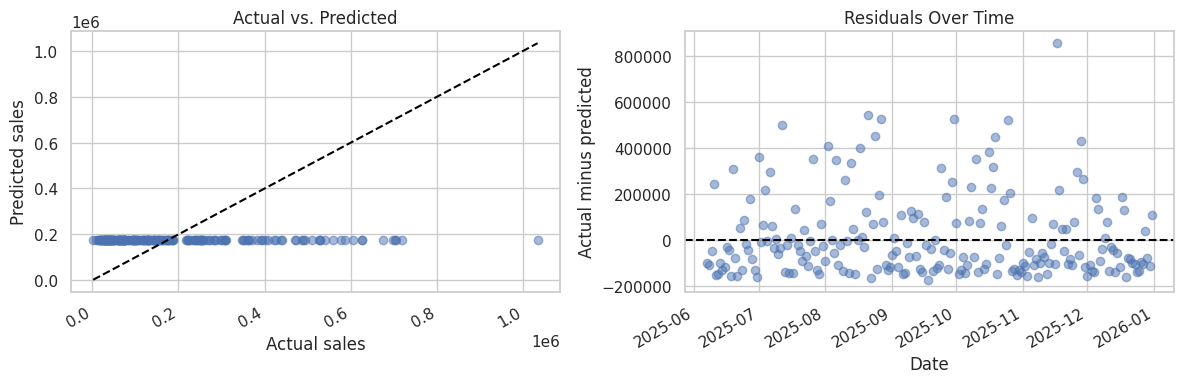

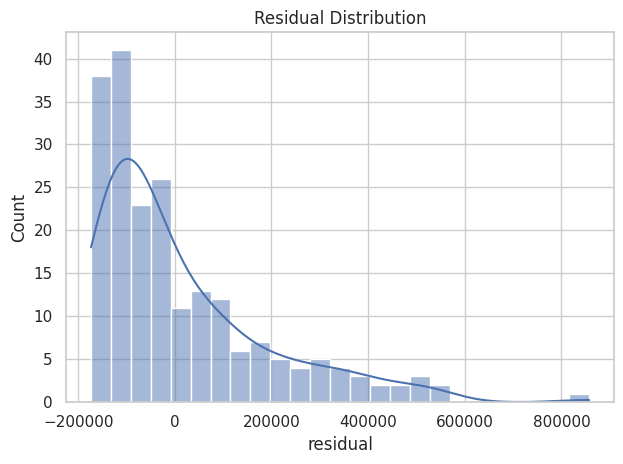

In [9]:
prediction_results = pd.DataFrame({'date': test['date'].to_numpy(),
    'actual_sales': y_test.to_numpy(), 'predicted_sales': predictions})
prediction_results['residual'] = prediction_results['actual_sales'] - prediction_results['predicted_sales']
prediction_results['absolute_error'] = prediction_results['residual'].abs()
display(prediction_results.head(10).round(2))
prediction_results.plot(x='date', y=['actual_sales', 'predicted_sales'], figsize=(13, 5), title=f'One-Day-Ahead Sales — {best_name}')
plt.ylabel('Sales'); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(prediction_results['actual_sales'], predictions, alpha=0.5)
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Actual sales', ylabel='Predicted sales', title='Actual vs. Predicted')
axes[1].scatter(prediction_results['date'], prediction_results['residual'], alpha=0.5)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(xlabel='Date', ylabel='Actual minus predicted', title='Residuals Over Time')
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
sns.histplot(prediction_results['residual'], bins=25, kde=True)
plt.title('Residual Distribution'); plt.tight_layout(); plt.show()

## 8. Feature importance on validation data
For a consistent ML diagnostic, inspect the machine-learning candidate with the best validation RMSE. Compute permutation importance on the last validation fold, without accessing the test set. A historical benchmark may still be the overall winner. Importance measures predictive reliance, not causation.

Validation feature importance for: Ridge alpha=10000


,feature,importance,std
17,sales_rolling_mean_14,42.573240,38.415525
21,sales_rolling_median_28,19.660313,13.039247
18,sales_rolling_median_14,18.111529,21.707413
10,sales_lag_1,15.634494,30.186245
20,sales_rolling_mean_28,14.636416,10.710636
12,sales_lag_14,10.468375,2.991422
25,sales_rolling_std_56,9.988206,9.869489
11,sales_lag_7,9.868141,38.747297
23,sales_rolling_mean_56,8.058918,10.644320
4,day_of_week_sin,4.540464,12.866559


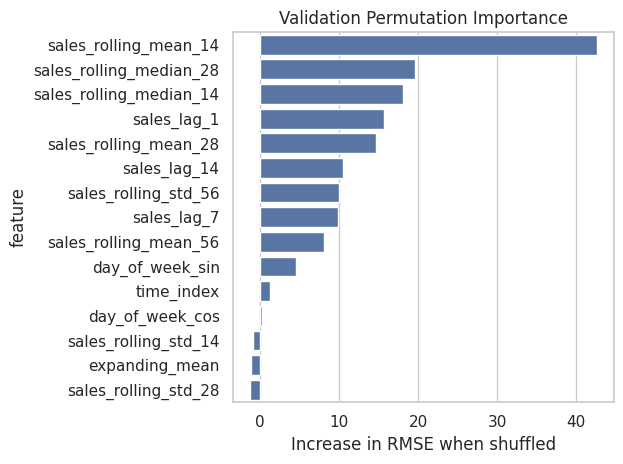

In [10]:
best_ml_name = next(name for name in validation['Model'] if name in estimators)
fit_idx, val_idx = list(cv.split(X_train))[-1]
importance_model = clone(estimators[best_ml_name]).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
permuted = permutation_importance(importance_model, X_train.iloc[val_idx], y_train.iloc[val_idx],
    scoring='neg_root_mean_squared_error', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({'feature': feature_columns,
    'importance': permuted.importances_mean, 'std': permuted.importances_std}).sort_values('importance', ascending=False)
print('Validation feature importance for:', best_ml_name)
display(importance.head(15))
sns.barplot(data=importance.head(15), x='importance', y='feature')
plt.title('Validation Permutation Importance'); plt.xlabel('Increase in RMSE when shuffled')
plt.tight_layout(); plt.show()

## 9. Evidence-based conclusion
Results below are generated from this run. A negative R² means the predictions perform worse than a constant equal to the test-period mean (a retrospective reference, unavailable in advance). The training-mean benchmark is a deployable comparison. Weak accuracy is a valid finding: do not claim operational readiness or change the data to inflate scores.

In [11]:
print(f'Selected model: {best_name}')
print(f"Test MAE: {selected_scores['MAE']:,.2f}")
print(f"Test RMSE: {selected_scores['RMSE']:,.2f}")
print(f"Test R²: {selected_scores['R2']:.4f}")
training_mean_rmse = comparison.loc[comparison['Model'].eq('Training mean'), 'RMSE'].iloc[0]
print(f"RMSE improvement over training-mean benchmark: {100*(1-selected_scores['RMSE']/training_mean_rmse):.2f}%")
print(f"Mean residual: {prediction_results['residual'].mean():,.2f}; negative means average overprediction.")
if selected_scores['R2'] <= 0:
    print('Conclusion: daily forecasts remain weak. The workflow is complete, but reliable business forecasting is not established.')
else:
    print('Conclusion: positive test R² provides evidence of predictive signal on this period, with uncertainty on future periods.')
print('Use for staffing or inventory only after further validation; promotions, stockouts, and order-volume drivers may improve forecasts.')
print('Limitations: synthetic transactions, limited daily history, zero-fill assumption, and one-day-ahead evaluation using observed preceding days.')

Selected model: Training mean
Test MAE: 134,726.90
Test RMSE: 179,946.37
Test R²: -0.0049
RMSE improvement over training-mean benchmark: 0.00%
Mean residual: 12,611.75; negative means average overprediction.
Conclusion: daily forecasts remain weak. The workflow is complete, but reliable business forecasting is not established.
Use for staffing or inventory only after further validation; promotions, stockouts, and order-volume drivers may improve forecasts.
Limitations: synthetic transactions, limited daily history, zero-fill assumption, and one-day-ahead evaluation using observed preceding days.


## 10. Export results

In [12]:
validation.to_csv(OUTPUT_DIR / 'validation_model_comparison.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'model_evaluation_comparison.csv', index=False)
importance.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
prediction_results.to_csv(OUTPUT_DIR / 'actual_vs_predicted_sales.csv', index=False)
with (OUTPUT_DIR / 'evaluation_summary.json').open('w') as f:
    json.dump({'selected_model': best_name, 'selection_rule': 'lowest expanding-window validation RMSE',
        'test_metrics': {k: float(v) for k, v in selected_scores.items()},
        'test_start': str(test['date'].min().date()), 'test_end': str(test['date'].max().date())}, f, indent=2)
print('Saved results to:', OUTPUT_DIR)
for name in ['validation_model_comparison.csv', 'model_evaluation_comparison.csv', 'feature_importance.csv', 'actual_vs_predicted_sales.csv', 'evaluation_summary.json']:
    print('-', name)

Saved results to: /content/drive/MyDrive/Week2Assign/Task3_Outputs
- validation_model_comparison.csv
- model_evaluation_comparison.csv
- feature_importance.csv
- actual_vs_predicted_sales.csv
- evaluation_summary.json
